# Homework 3 - Aprendizagem

>Teresa Matos- ist1106009   
>Francisco Morão - ist1106067   
>Grupo 46   

## II. Programming

In the next exercise you will use the accounts.csv dataset. This dataset contains account details 
of bank clients, and the target variable y is binary (‘has the client subscribed a term deposit?’).


1) [4v] Select the first 8 features and remove duplicates and null values. Normalize the data 
using MinMaxScaler. Using sklearn, apply k-means clustering (without targets) on the 
normalized data with k= {2,3,4,5,6,7,8}. Apply k-means randomly initialized, using max_iter 
= 500 and random_state = 42. Plot the different sum of squared errors (SSE) using the 
_inertia attribute of k-means according to the number of clusters. 
Hint: You can use get_dummies() to change the feature type from categorical to numerical 
(e.g. pd.get_dummies(data, drop_first=True)).

/usr/lib/python3/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/lib/python3/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/lib/python3/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/lib/python3/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/lib/python3/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_in

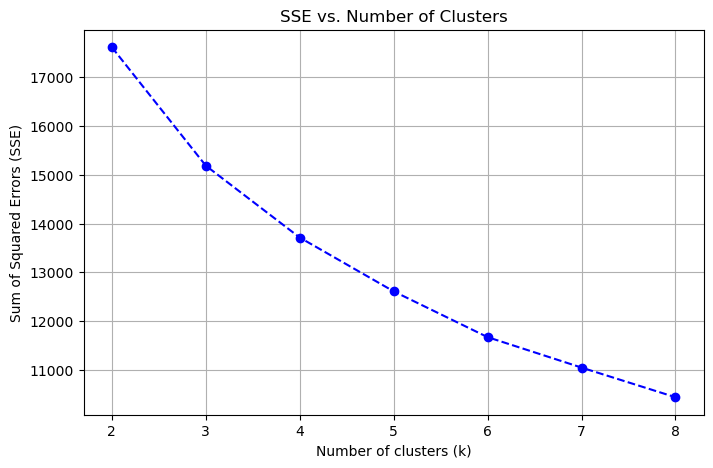

In [2]:
# Import necessary libraries
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Load dataset (assuming you have already loaded accounts.csv as a pandas dataframe)
data = pd.read_csv('accounts.csv')

# Step 1: Select the first 8 features
selected_features = ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan']
data_selected = data[selected_features]

# Step 2: Handle categorical variables by using get_dummies
data_encoded = pd.get_dummies(data_selected, drop_first=True)

# Step 3: Remove duplicates and null values
data_cleaned = data_encoded.drop_duplicates().dropna()

# Step 4: Normalize the data using MinMaxScaler
scaler = MinMaxScaler()
data_normalized = scaler.fit_transform(data_cleaned)

# Step 5: Apply K-Means clustering for k = {2, 3, 4, 5, 6, 7, 8}
SSE = []
k_values = range(2, 9)
for k in k_values:
    kmeans = KMeans(n_clusters=k, max_iter=500, random_state=42)
    kmeans.fit(data_normalized)
    SSE.append(kmeans.inertia_)  # inertia is the SSE for K-Means

# Step 6: Plot SSE vs number of clusters
plt.figure(figsize=(8,5))
plt.plot(k_values, SSE, marker='o', linestyle='--', color='b')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Sum of Squared Errors (SSE)')
plt.title('SSE vs. Number of Clusters')
plt.grid(True)
plt.show()


2) [1.5v] According to the previous plot, how many underlying customer segments (clusters) 
should there be ? Explain based on the trade off between the clusters and inertia

3) [1.5v] Would k-modes be a better clustering approach ? Explain why based on the dataset 
features.

4) [2v] Apply PCA to the data : 
a. Use StandardScaler to scale the data before you apply fit_transform. How much 
variability is explained by the top 2 components ? 
b. Provide a scatterplot according to the first 2 principal components and color the 
points according to k=3 clusters. Can we clearly separate the clusters ? Justify